# Catorce predictores en diez pliegues: qué puntúa cada uno y dónde se niega cada uno

**Pregunta:** ¿Por qué se niega cada predictor donde lo hace, y cómo se ordenan los predictores en las filas que todos responden?

**Nivel 2: El método en la práctica** · Requiere: 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites · Tiempo de lectura: unos 35 minutos

## Objetivos

El benchmark del producto corre catorce predictores: dos controles, la familia clásica, los estadísticos y el nivel aprendido. Cada uno responde un tiro con un número o con una negativa declarada, y una negativa es un resultado, nunca se promedia. Este notebook corre toda la escalera por los diez pliegues que dejan fuera una campaña, clasifica cada negativa según su causa y pregunta cómo se ordenan los predictores cuando se los compara en las mismas filas.

Al terminar habrá:

- corrido los catorce predictores pliegue a pliegue, un nivel a la vez, y puntuado cada uno en las filas que respondió;
- dibujado la matriz de negativas por predictor y campaña y nombrado las tres causas de una negativa;
- visto los valores que devolvió un modelo cuando el motor los rechazó, frente al rango plausible de un tamaño de fragmento;
- vuelto a puntuar cada predictor de tamaño en las 79 filas que todos respondieron y leído qué le hace eso al orden.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación importa los paquetes, imprime sus versiones, carga el corpus y define `Table`, que muestra filas como tabla Markdown en Jupyter y como texto alineado en otro lugar. También importa `json` para la única comprobación de reproducción del final.

In [1]:
# Importaciones, versiones de los paquetes y el cargador del corpus
from importlib.metadata import version
from pathlib import Path
import json

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
print(len(train), "tiros de", len({b.site for b in train}), "campañas")

class Table:
    """Filas bajo un encabezado, mostradas como tabla Markdown"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2
97 tiros de 10 campañas


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los catorce predictores tal como se publicaron | Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3; Sui et al. 2025, https://doi.org/10.3390/app15031254; y los artículos citados en el tema 02 | los métodos se citan, el motor los implementa | `bf.default_arms()` |
| Los puntajes agrupados que escribió la ejecución offline, para la única comprobación de reproducción | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json`, campo `protocols` |

## Método

Un predictor se niega por una de tres causas, y el motor declara cada una en lugar de esconderla:

1. **No se puede conocer una entrada necesaria (A).** La familia clásica necesita un volumen de roca y una masa de carga, que salen del diámetro de perforación. Una campaña que no publica ninguno no puede entregarlos, y el motor no inventa un bordo.
2. **No es un predictor de tamaño (B).** El discriminante de grupo asigna un grupo de rigidez de la roca; por diseño nunca devuelve un tamaño.
3. **La salida sale del rango físico (C).** Un tamaño medio de fragmento está entre un milímetro y unos pocos metros. Un modelo que devuelve un número fuera de `bf.models.PLAUSIBLE_X50_M` salió de su dominio, y el motor rechaza el número en lugar de puntuarlo. Sin esa protección, una ley de potencia reajustada que extrapola se puntuaría con sus números absurdos y arrasaría el valor agrupado del predictor.

Como los predictores responden distinto número de filas, un puntaje agrupado sobre las filas propias de cada uno compara denominadores distintos. La comparación justa es sobre las filas que todos los predictores de tamaño respondieron, las filas comunes, que se informan junto al puntaje propio del predictor y nunca como veredicto, pues las filas las elige la propia negativa de los predictores. El puntaje en todo el notebook es `r2_identity`, la varianza explicada respecto de la línea 1:1, con la campaña excluida en cada pliegue.

### Paso 1: los diez pliegues y los cuatro niveles

`leave_one_site_out` entrega diez particiones, una por campaña. Cada predictor se construye de nuevo en cada pliegue con su fábrica de `bf.default_arms()`, porque reutilizar una instancia dejaría que el ajuste de un pliegue se filtre al siguiente. La celda lista los pliegues y los cuatro niveles de la escalera.

In [2]:
# Los diez pliegues leave-one-site-out y el nivel de cada uno de los catorce predictores
folds = list(bf.leave_one_site_out(train))
tested = [blast for fold in folds for blast in fold.test]
factories = bf.default_arms()
tiers = {name: make().tier for name, make in factories.items()}
print(len(folds), "pliegues,", len(tested),
    "tiros fuera de pliegue, cada predictor se construye de nuevo en cada pliegue")
for tier in ("control", "classical", "statistical", "learned"):
    print(f"{tier:<12}", [name for name, t in tiers.items() if t == tier])

10 pliegues, 97 tiros fuera de pliegue, cada predictor se construye de nuevo en cada pliegue
control      ['null', 'oracle']
classical    ['kuznetsov', 'kuznetsov-transfer', 'kuznetsov-capped']
statistical  ['group-discriminant', 'published-regression', 'refitted-regression']
learned      ['published-neural-net', 'svr-rbf', 'svr-poly', 'random-forest', 'xgboost', 'stacking']


### Paso 2: correr la escalera, nivel por nivel

El primer nivel contiene los controles (el nulo, que predice la media de entrenamiento, y el oráculo, al que se le entrega el tamaño verdadero y acota el puntaje por arriba) y las tres variantes de la ecuación clásica. La celda corre cada uno por los diez pliegues, agrupa las respuestas fuera de pliegue y las puntúa, e imprime con qué se ajustó el predictor clásico.

In [3]:
# Controles y familia clásica en los diez pliegues
predictions = {}
for name in [n for n, tier in tiers.items() if tier in ("control", "classical")]:
    predictions[name] = [p for fold in folds for p in factories[name]().fit(fold.train).predict(fold.test)]
scores = {name: bf.score(tested, predictions[name], method=name) for name in predictions}
print("kuznetsov, ajustado con:", factories["kuznetsov"]().fitted_on)
rows = [(n, s.n_scored, s.n_abstained, f"{s.r2_identity:.3f}", f"{s.rmse_m:.3f}") for n, s in scores.items()]
Table(["predictor", "respondidos", "negados", "r2", "RMSE (m)"], rows)

kuznetsov, ajustado con: nothing in any split: the per-site rock factor is back-solved from the 2012 paper's published Kuz-Ram predictions for that site's own hold-out blasts


| predictor | respondidos | negados | r2 | RMSE (m) |
|---|---|---|---|---|
| null | 97 | 0 | -0.216 | 0.207 |
| oracle | 97 | 0 | 1.000 | 0.000 |
| kuznetsov | 91 | 6 | 0.311 | 0.153 |
| kuznetsov-transfer | 91 | 6 | 0.298 | 0.154 |
| kuznetsov-capped | 91 | 6 | 0.352 | 0.148 |

El nivel estadístico contiene el discriminante de grupo, la regresión publicada de Hudaverdi et al. 2010 y un reajuste de esa ley de potencia con las filas de entrenamiento de cada pliegue. La celda corre los tres e imprime con qué se ajustó la regresión publicada, porque eso decide cómo se lee su puntaje.

In [4]:
# El nivel estadístico en los mismos pliegues; el discriminante nunca responde un tamaño
for name in [n for n, tier in tiers.items() if tier == "statistical"]:
    predictions[name] = [p for fold in folds for p in factories[name]().fit(fold.train).predict(fold.test)]
    scores[name] = bf.score(tested, predictions[name], method=name)
print("published-regression, ajustado con:", factories["published-regression"]().fitted_on)
rows = [(n, s.n_scored, s.n_abstained, f"{s.r2_identity:.3f}" if s.n_scored else "-",
    f"{s.rmse_m:.3f}" if s.n_scored else "-")
        for n, s in scores.items() if tiers[n] == "statistical"]
Table(["predictor", "respondidos", "negados", "r2", "RMSE (m)"], rows)

published-regression, ajustado con: all 97 blasts of the training corpus, by Hudaverdi et al. 2010


| predictor | respondidos | negados | r2 | RMSE (m) |
|---|---|---|---|---|
| group-discriminant | 0 | 97 | - | - |
| published-regression | 97 | 0 | 0.802 | 0.083 |
| refitted-regression | 93 | 4 | -4.075 | 0.431 |

El nivel aprendido contiene los seis predictores del notebook 01. Cada uno se reajusta en cada uno de los diez pliegues, así que esta es la celda más lenta del notebook.

In [5]:
# El nivel aprendido: seis predictores reajustados en cada uno de los diez pliegues, unos quince segundos
for name in [n for n, tier in tiers.items() if tier == "learned"]:
    predictions[name] = [p for fold in folds for p in factories[name]().fit(fold.train).predict(fold.test)]
    scores[name] = bf.score(tested, predictions[name], method=name)
rows = [(n, s.n_scored, s.n_abstained, f"{s.r2_identity:.3f}", f"{s.rmse_m:.3f}") for n,
    s in scores.items() if tiers[n] == "learned"]
Table(["predictor", "respondidos", "negados", "r2", "RMSE (m)"], rows)

| predictor | respondidos | negados | r2 | RMSE (m) |
|---|---|---|---|---|
| published-neural-net | 97 | 0 | -0.626 | 0.239 |
| svr-rbf | 96 | 1 | -0.387 | 0.221 |
| svr-poly | 86 | 11 | -4.546 | 0.432 |
| random-forest | 97 | 0 | -0.231 | 0.208 |
| xgboost | 97 | 0 | -0.034 | 0.191 |
| stacking | 97 | 0 | -0.035 | 0.191 |

**Qué muestran las tres tablas.** El oráculo puntúa 1,000 sin error, como debe un control, y el nulo puntúa -0,216 con un RMSE de 0,207 m: agrupado en diez campañas, incluso la media de entrenamiento se equivoca en una quinta parte de metro. La ecuación clásica y sus dos variantes puntúan 0,311, 0,298 y 0,352 en los 91 tiros que responden. La regresión publicada puntúa 0,802, pero la línea impresa arriba dice que se ajustó con los 97 tiros del corpus, así que ese número es un ajuste a estas filas y no una predicción para una campaña que no vio. Lo mismo vale, de forma más débil, para el predictor clásico, cuyo factor de roca por sitio se despeja de las predicciones publicadas por la fuente para ese sitio. Entre los aprendidos solo boosting (-0,034) y el apilamiento (-0,035) se acercan a cero; la red puntúa -0,626, el bosque -0,231, el regresor de vectores de soporte radial -0,387 y el polinómico -4,546. **Qué no muestran las tablas:** cuántas filas dejó sin responder cada predictor, que es el paso siguiente.

### Paso 3: cada negativa, con su causa

La causa A depende de lo que cada campaña publica sobre su geometría. La primera celda le pregunta al motor, con `has_absolute_geometry`, qué campañas fijan una escala absoluta, y lista el diámetro de perforación que publica cada una. La segunda celda cuenta cada negativa por predictor y campaña y nombra su tipo a partir del texto de razón del propio motor. La figura dibuja el resultado como una matriz.

In [6]:
# Qué publica cada campaña de su geometría, y por tanto en cuáles puede correr la familia clásica
sites = sorted({blast.site for blast in train})
rows = []
for site in sites:
    first = next(blast for blast in train if blast.site == site)
    diameter = bf.SITE_GEOMETRY[site].hole_diameter_mm
    rows.append((site, "sí" if bf.has_absolute_geometry(first) else "no", diameter if diameter else "-"))
Table(["campaña", "escala fijada", "diámetro de perforación (mm)"], rows)

| campaña | escala fijada | diámetro de perforación (mm) |
|---|---|---|
| Akdaglar | sí | 89.0 |
| Dongri-Buzurg | sí | 100.0 |
| Enusa | sí | 165.0 |
| Miami | no | - |
| Mrica | sí | 76.0 |
| Murgul | sí | 165.0 |
| Ozmert | sí | 89.0 |
| Reocin | sí | 229.0 |
| Reocin-UG | sí | 91.2 |
| Soma | sí | 210.0 |

La celda siguiente clasifica cada negativa de la escalera. Cuenta, para cada predictor y campaña, los tiros que volvieron sin tamaño, y nombra el tipo de negativa (A, B o C de la sección Método) buscando una frase en el texto de razón que adjuntó el motor. El resultado es la matriz que dibuja la figura.

In [7]:
# Contar las negativas de cada predictor por campaña y nombrar su tipo a partir del texto de razón del motor
KINDS = {"publishes no hole diameter": "A", "assigns a rock-stiffness group": "B", "outside the plausible": "C"}
refusals = {name: {} for name in predictions}
kind_of = {}
for name, preds in predictions.items():
    for blast, p in zip(tested, preds):
        if p.abstained:
            refusals[name][blast.site] = refusals[name].get(blast.site, 0) + 1
            kind_of[name] = next(kind for text, kind in KINDS.items() if text in p.abstain_reason)
refusing = [name for name in predictions if refusals[name]]
matrix = np.array([[refusals[name].get(site, 0) for site in sites] for name in refusing])
print({name: kind_of[name] for name in refusing})
print("negativas en total:", int(matrix.sum()), "de", len(refusing) * len(tested),
    "respuestas posibles de estos predictores")

{'kuznetsov': 'A', 'kuznetsov-transfer': 'A', 'kuznetsov-capped': 'A', 'group-discriminant': 'B', 'refitted-regression': 'C', 'svr-rbf': 'C', 'svr-poly': 'C'}
negativas en total: 131 de 679 respuestas posibles de estos predictores


La celda siguiente dibuja la matriz: una fila por predictor que se negó en algún lugar, una columna por campaña excluida, el conteo de tiros negados en cada celda y el tipo de negativa en la etiqueta de la fila. Busque filas que llenan una columna, filas que llenan todas las columnas y filas dispersas.

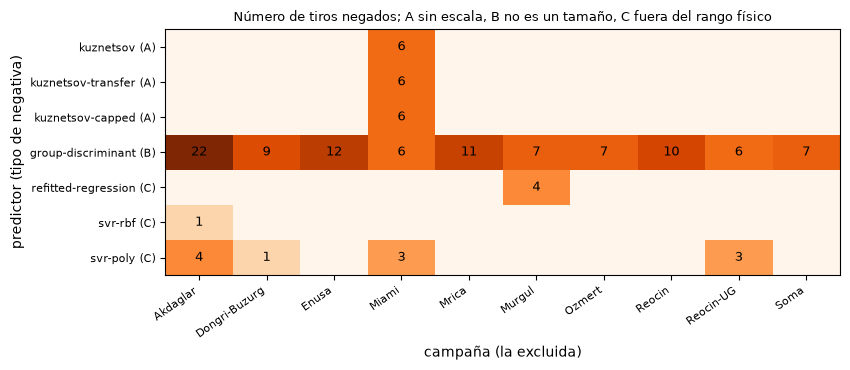

In [8]:
# Matriz de negativas: predictores que se niegan contra la campaña donde se niegan
fig, ax = plt.subplots(figsize=(8.6, 3.8))
image = ax.imshow(np.log10(matrix + 1), cmap="Oranges", aspect="auto")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        if matrix[i, j]:
            ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=9)
ax.set_xticks(range(len(sites)), sites, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(refusing)), [f"{name} ({kind_of[name]})" for name in refusing], fontsize=8)
ax.set_xlabel("campaña (la excluida)")
ax.set_ylabel("predictor (tipo de negativa)")
ax.set_title("Número de tiros negados; A sin escala, B no es un tamaño, C fuera del rango físico", fontsize=9)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Siete predictores se niegan en algún lugar, 131 veces de las 679 respuestas que pudieron dar. La causa A es una columna: Miami no publica diámetro de perforación, y las tres variantes clásicas se niegan en sus seis tiros, y en nada más. La causa B es una fila: el discriminante de grupo se niega en los 97 tiros, en toda campaña, porque devuelve un grupo y no un tamaño. La causa C está repartida: la regresión reajustada se niega en cuatro tiros de Murgul, el regresor de vectores de soporte radial en un tiro de Akdaglar (-0,003096 m) y el polinómico en once tiros de cuatro campañas. **Qué no muestra:** cuán malos eran los números rechazados, lo que mide el paso siguiente. **Qué se sigue:** el puntaje de un predictor solo puede leerse junto con su fila de esta matriz.

### Paso 4: los números que la protección rechazó

Una negativa de tipo C lleva en su texto de razón el valor que devolvió el modelo. La celda recupera esos valores, imprime el rango plausible del motor, y la figura los pone en un eje logarítmico simétrico junto a las predicciones aceptadas del mismo predictor y la banda plausible.

In [9]:
# Los números que el guardián negó: el valor que devolvió el modelo, tomado del texto de la razón
low, high = bf.models.PLAUSIBLE_X50_M
returned = {}
for name in refusing:
    if kind_of[name] == "C":
        reasons = [p.abstain_reason for p in predictions[name] if p.abstained]
        returned[name] = [float(reason.split("returned ")[1].split(" m")[0]) for reason in reasons]
print("rango plausible de un tamaño medio de fragmento (m):", low, "a", high)
rows = [(n, len(v), f"{min(v):.4g}", f"{max(v):.4g}") for n, v in returned.items()]
Table(["predictor", "negados", "menor devuelto (m)", "mayor devuelto (m)"], rows)

rango plausible de un tamaño medio de fragmento (m): 0.001 a 3.0


| predictor | negados | menor devuelto (m) | mayor devuelto (m) |
|---|---|---|---|
| refitted-regression | 4 | 6.065 | 10.48 |
| svr-rbf | 1 | -0.003096 | -0.003096 |
| svr-poly | 11 | -0.313 | 18.9 |

La celda siguiente ubica los valores negados en un eje logarítmico simétrico, que mantiene legibles tanto los números negativos pequeños como los valores cercanos a 10 m, junto a las predicciones aceptadas del mismo predictor y la banda plausible verde. Mire cuán lejos de la banda caen los valores negados.

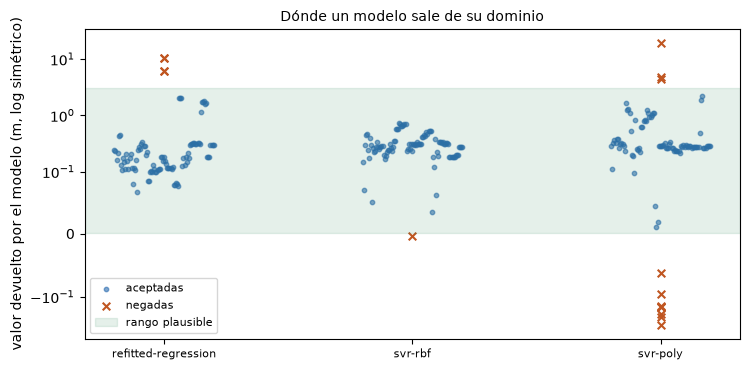

In [10]:
# Valores devueltos contra la banda plausible, con las predicciones aceptadas del mismo predictor
fig, ax = plt.subplots(figsize=(7.6, 3.8))
for k, (name, values) in enumerate(returned.items()):
    accepted = [p.x50_m for p in predictions[name] if not p.abstained]
    ax.scatter(np.full(len(accepted), k) + np.linspace(-0.2, 0.2, len(accepted)), accepted, s=10, color="#2b6cb0",
        alpha=0.6,
               label="aceptadas" if k == 0 else None)
    ax.scatter(np.full(len(values), k), values, s=30, marker="x", color="#c05621",
        label="negadas" if k == 0 else None)
ax.axhspan(low, high, color="#2f855a", alpha=0.12, label="rango plausible")
ax.set_yscale("symlog", linthresh=0.1)
ax.set_xticks(range(len(returned)), list(returned), fontsize=8)
ax.set_ylabel("valor devuelto por el modelo (m, log simétrico)")
ax.set_title("Dónde un modelo sale de su dominio", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Cada valor rechazado (cruz naranja) cae fuera de la banda verde, y las predicciones aceptadas (azul) están dentro de ella, sobre todo entre 0,1 m y 1 m. La regresión reajustada devolvió tamaños de fragmento de 6,065 m y 10,48 m en Murgul; el regresor de vectores de soporte polinómico devolvió valores tan grandes como 18,9 m y tan pequeños como -0,313 m, un tamaño de fragmento negativo. **Qué no muestra:** que todo valor aceptado sea correcto: la banda solo atrapa lo imposible, no lo errado. **Qué se sigue:** estos predictores salieron del rango físico en una campaña distinta de sus filas de entrenamiento, y la protección convirtió aritmética en una negativa contada. Puntuar esos números habría hecho que el r2 agrupado del predictor dependiera de un puñado de valores absurdos.

### Paso 5: la comparación justa en las filas comunes

La celda conserva las filas que respondieron los doce predictores de tamaño (el discriminante nunca responde y el oráculo es un control, no un competidor), informa qué filas debieron salir, y puntúa cada predictor solo en esas filas. La figura pone ese puntaje junto al de las filas propias del predictor, recortado en -2 para que los peores no aplasten al resto.

In [11]:
# Filas que todos los predictores de tamaño respondieron, y cada predictor puntuado solo en ellas
sizers = [name for name in predictions if name not in ("group-discriminant", "oracle")]
common = [i for i in range(len(tested)) if all(not predictions[name][i].abstained for name in sizers)]
print(len(common), "filas comunes de", len({tested[i].site for i in common}), "campañas")
dropped = [tested[i].site for i in range(len(tested)) if i not in common]
print("filas fuera del conjunto común, por campaña:", {s: dropped.count(s) for s in sorted(set(dropped))})
on_common = {}
for name in sizers:
    on_common[name] = bf.score([tested[i] for i in common], [predictions[name][i] for i in common], method=name)
rows = [(n, scores[n].n_scored, f"{scores[n].r2_identity:.3f}", f"{on_common[n].r2_identity:.3f}") for n in sizers]
Table(["predictor", "filas propias", "r2 filas propias", "r2 filas comunes"], rows)

79 filas comunes de 9 campañas
filas fuera del conjunto común, por campaña: {'Akdaglar': 4, 'Dongri-Buzurg': 1, 'Miami': 6, 'Murgul': 4, 'Reocin-UG': 3}


| predictor | filas propias | r2 filas propias | r2 filas comunes |
|---|---|---|---|
| null | 97 | -0.216 | -0.229 |
| kuznetsov | 91 | 0.311 | 0.318 |
| kuznetsov-transfer | 91 | 0.298 | 0.293 |
| kuznetsov-capped | 91 | 0.352 | 0.364 |
| published-regression | 97 | 0.802 | 0.766 |
| refitted-regression | 93 | -4.075 | -3.715 |
| published-neural-net | 97 | -0.626 | -0.491 |
| svr-rbf | 96 | -0.387 | -0.329 |
| svr-poly | 86 | -4.546 | -4.837 |
| random-forest | 97 | -0.231 | -0.167 |
| xgboost | 97 | -0.034 | 0.212 |
| stacking | 97 | -0.035 | 0.215 |

La celda siguiente pone el puntaje agrupado de cada predictor en sus filas propias junto a su puntaje en las filas comunes, en orden descendente del segundo, y recorta ambos en -2 para que los peores predictores no aplasten la escala. Mire qué barras se mueven entre los dos y cuáles no.

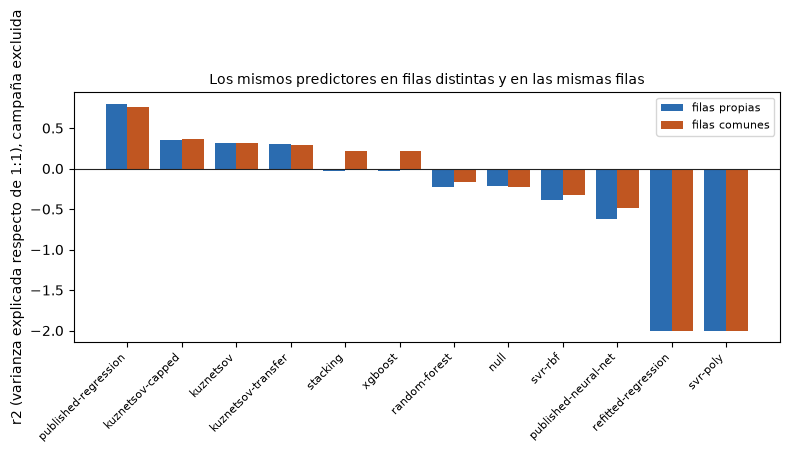

In [12]:
# Puntaje agrupado en las filas propias de cada predictor frente al puntaje en las filas comunes, recortado en -2
ranked = sorted(sizers, key=lambda name: -on_common[name].r2_identity)
x = np.arange(len(ranked))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, [max(scores[n].r2_identity, -2) for n in ranked], 0.4, color="#2b6cb0", label="filas propias")
ax.bar(x + 0.2, [max(on_common[n].r2_identity, -2) for n in ranked], 0.4, color="#c05621", label="filas comunes")
ax.axhline(0, color="#222", lw=0.8)
ax.set_xticks(x, ranked, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("r2 (varianza explicada respecto de 1:1), campaña excluida")
ax.set_title("Los mismos predictores en filas distintas y en las mismas filas", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** En las 79 filas comunes el orden cambia de magnitud pero poco de posición. Gradient boosting y el apilamiento pasan de -0,034 y -0,035 a +0,212 y +0,215, porque las filas que salen del conjunto incluyen los seis tiros de Miami y los tiros donde se negaron los predictores más débiles (Akdaglar 4, Murgul 4, Reocin-UG 3, Dongri-Buzurg 1). Las variantes clásicas casi no se mueven (0,311 a 0,318, 0,298 a 0,293, 0,352 a 0,364). Cuatro predictores siguen bajo el nulo en las filas comunes: la regresión reajustada (-3,715), el regresor de vectores de soporte polinómico (-4,837), la red (-0,491) y el regresor de vectores de soporte radial (-0,329). **Qué no muestra:** un veredicto. Las filas dependen de quién se negó, así que un predictor que se niega en sus filas difíciles se ve mejor en las que conserva.

### Comprobación de reproducción: los puntajes agrupados de la ejecución offline

Esta corrida es la misma que hace la ejecución offline, así que sus puntajes agrupados deben igualar a los escritos en `benchmark.json`. La celda toma la mayor diferencia sobre todos los predictores que tienen puntaje.

In [13]:
# La única comprobación de reproducción: cada puntaje agrupado iguala al que escribió la ejecución offline
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
loso = benchmark["protocols"]["leave-one-site-out"]["arms"]
rescored = {n: bf.score(tested, predictions[n], method=n).r2_identity for n in predictions}
gaps = [abs(r2 - loso[n]["r2_identity"]) for n, r2 in rescored.items() if r2 is not None]
print("mayor diferencia con los puntajes agrupados de la ejecución offline en",
      len(gaps), "predictores:", f"{max(gaps):.1e}")

mayor diferencia con los puntajes agrupados de la ejecución offline en 13 predictores: 0.0e+00


## Resultados

**Respuesta:** cada predictor se niega por una de tres razones que el motor declara, y en las filas que todos responden solo el bosque, boosting y el apilamiento superan al nulo entre los predictores aprendidos. Falta una entrada necesaria (A: Miami no tiene diámetro de perforación, así que las tres variantes clásicas se niegan en sus 6 tiros), el predictor no es un predictor de tamaño (B: el discriminante de grupo se niega en los 97), o su número sale del rango físico de 0,001 m a 3,0 m (C: la regresión reajustada en 4 tiros, el regresor de vectores de soporte radial en 1, el polinómico en 11). Agrupadas en las filas propias de cada predictor, las variantes clásicas puntúan 0,311, 0,298 y 0,352, boosting -0,034 y el nulo -0,216; en las 79 filas comunes boosting y el apilamiento llegan a 0,212 y 0,215, el bosque a -0,167, las variantes clásicas quedan en 0,318, 0,293 y 0,364, y la red, ambos regresores de vectores de soporte y la regresión reajustada siguen bajo el nulo (-0,229).

Los puntajes de la regresión publicada (0,802) y de las variantes clásicas no son números fuera de muestra en el mismo sentido que los de los aprendidos: la primera se ajustó con estas filas y las segundas toman su factor de roca de las predicciones publicadas por la propia fuente. La lectura honesta del orden es por tanto breve: ningún predictor aprendido supera a la ecuación clásica con la campaña excluida, y los mejores aprendidos, boosting y el apilamiento, puntúan cerca de cero en todas las filas.

**Qué no muestra esto.** El puntaje en filas comunes es un diagnóstico, no un orden, porque las filas comunes son las que nadie se negó a responder. Tampoco decide el notebook qué criterio debe cumplir un predictor; eso es el criterio declarado de antemano del tema 04. Y los conteos de negativas describen este corpus, diez campañas, una de las cuales no publica geometría.

## Resumen

- Los catorce predictores corren por los diez pliegues, cada uno reconstruido de nuevo en cada pliegue, y el puntaje agrupado de cada uno se informa con sus negativas.
- Una negativa tiene una de tres causas: una entrada que no se puede conocer (Miami), un predictor que no es de tamaño (el discriminante) o una salida fuera de 0,001 m a 3,0 m (regresión reajustada, ambos regresores de vectores de soporte).
- En las 79 filas que todos los predictores de tamaño respondieron, boosting y el apilamiento llegan a 0,212 y 0,215 y cuatro predictores siguen bajo el nulo.
- Siguiente: el notebook 03 reproduce la red neuronal publicada y pregunta cuánto vale su puntaje de validación publicado (nivel 3).

## Referencias

- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (la red de retropropagación y su conjunto de validación)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (vectores de soporte polinómico, bosque, boosting, apilamiento)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y la regresión publicada)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/